# CodeAlpha Internship – Task 2
# Student Performance Analysis: Exploratory Data Analysis (EDA)

## 1. Introduction

Student performance analysis helps us understand factors associated with academic achievement.

The objective of this project is to explore student performance data, examine patterns, analyze relationships between variables, and identify factors associated with students' final grades.

This notebook focuses on **Exploratory Data Analysis (EDA)** and statistical analysis.

## 1.1 Research Questions

Before performing the exploratory data analysis, the following research questions were identified:

1. Does study time have an association with students' final grades?
2. How do previous academic failures relate to final grades?
3. Is there a relationship between student absences and final academic performance?
4. How strongly are previous period grades (G1 and G2) associated with final grades (G3)?
5. Do family background and lifestyle factors show any patterns in students' academic performance?
6. Are there any unusual values or potential outliers in the dataset?

These questions guide the exploratory analysis and help identify meaningful patterns and relationships within the student performance dataset.

## 2. Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


## 3. Loading the Dataset

In [ ]:
url = "https://raw.githubusercontent.com/MakroMB/student-performance-analysis/main/data/student-por.csv"
df = pd.read_csv(url, sep=";")
print("Dataset loaded successfully!")


Dataset loaded successfully!


## 4. Dataset Overview

The dataset contains information about students, their family background, lifestyle, study habits, and academic performance. It contains numerical and categorical variables. The final grade (**G3**) is used as the main outcome variable in this analysis.


In [ ]:
print("First five records:")
display(df.head())

print("\nDataset shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


First five records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13



Dataset shape:
Rows: 649
Columns: 33

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason 

## 5. Data Cleaning and Quality Assessment

The dataset is checked for missing values, duplicate records, data types, and values outside expected grade and absence ranges. These checks help assess data quality before further analysis.


In [ ]:
print("MISSING VALUES BY COLUMN")
display(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes)

print("\nDataset shape:", df.shape)


MISSING VALUES BY COLUMN


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Total missing values: 0

Duplicate records: 0

Data types:


,0
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object



Dataset shape: (649, 33)


### 5.1 Grade and Absence Validation

In [ ]:
grade_columns = ["G1", "G2", "G3"]

print("Grades outside the expected 0–20 range:")
display(((df[grade_columns] < 0) | (df[grade_columns] > 20)).sum())

print("Negative absence values:", (df["absences"] < 0).sum())


Grades outside the expected 0–20 range:


,0
G1,0
G2,0
G3,0


Negative absence values: 0


## 6. Descriptive Statistical Analysis

Descriptive statistics summarize numerical variables using count, mean, standard deviation, minimum, quartiles, and maximum values.


In [ ]:
print("DESCRIPTIVE STATISTICS FOR NUMERICAL VARIABLES")
display(df.describe().round(2))


DESCRIPTIVE STATISTICS FOR NUMERICAL VARIABLES


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


In [ ]:
print("FINAL GRADE (G3) SUMMARY")
display(df["G3"].describe().round(2))
print("Average final grade:", round(df["G3"].mean(), 2))
print("Median final grade:", round(df["G3"].median(), 2))
print("Highest final grade:", df["G3"].max())
print("Lowest final grade:", df["G3"].min())


FINAL GRADE (G3) SUMMARY


,G3
count,649.00
mean,11.91
std,3.23
min,0.00
25%,10.00
50%,12.00
75%,14.00
max,19.00


Average final grade: 11.91
Median final grade: 12.0
Highest final grade: 19
Lowest final grade: 0


## 7. Exploratory Analysis of Student-Related Factors

This section compares average final grades across selected study, academic, family, and lifestyle factors. These are descriptive comparisons and should not be interpreted as proof of cause and effect.


In [ ]:
print("AVERAGE FINAL GRADE BY STUDY TIME")
display(df.groupby("studytime")["G3"].agg(["mean", "count"]).round(2))

print("\nAVERAGE FINAL GRADE BY PREVIOUS FAILURES")
display(df.groupby("failures")["G3"].agg(["mean", "count"]).round(2))

print("\nFINAL GRADE SUMMARY BY ABSENCE COUNT")
display(df.groupby("absences")["G3"].agg(["mean", "count"]).head(15).round(2))

print("\nABSENCES DESCRIPTIVE SUMMARY")
display(df["absences"].describe().round(2))


AVERAGE FINAL GRADE BY STUDY TIME


,mean,count
studytime,,
1,10.84,212
2,12.09,305
3,13.23,97
4,13.06,35



AVERAGE FINAL GRADE BY PREVIOUS FAILURES


,mean,count
failures,,
0,12.51,549
1,8.64,70
2,8.81,16
3,8.07,14



FINAL GRADE SUMMARY BY ABSENCE COUNT


,mean,count
absences,,
0,12.04,244
1,12.42,12
2,12.19,110
3,10.43,7
4,12.01,93
5,11.75,12
6,12.12,49
7,13.00,3
8,11.62,42



ABSENCES DESCRIPTIVE SUMMARY


,absences
count,649.00
mean,3.66
std,4.64
min,0.00
25%,0.00
50%,2.00
75%,6.00
max,32.00


In [ ]:
print("AVERAGE FINAL GRADE BY MOTHER'S EDUCATION")
display(df.groupby("Medu")["G3"].agg(["mean", "count"]).round(2))

print("\nAVERAGE FINAL GRADE BY FATHER'S EDUCATION")
display(df.groupby("Fedu")["G3"].agg(["mean", "count"]).round(2))


AVERAGE FINAL GRADE BY MOTHER'S EDUCATION


,mean,count
Medu,,
0,11.67,6
1,10.80,143
2,11.66,186
3,11.92,139
4,13.07,175



AVERAGE FINAL GRADE BY FATHER'S EDUCATION


,mean,count
Fedu,,
0,12.14,7
1,10.94,174
2,11.78,209
3,12.38,131
4,12.92,128


In [ ]:
factors = ["famsize", "freetime", "goout", "health"]

for col in factors:
    print("\nAVERAGE FINAL GRADE BY", col.upper())
    display(df.groupby(col)["G3"].agg(["mean", "count"]).round(2))



AVERAGE FINAL GRADE BY FAMSIZE


,mean,count
famsize,,
GT3,11.81,457
LE3,12.13,192



AVERAGE FINAL GRADE BY FREETIME


,mean,count
freetime,,
1,11.73,45
2,12.71,107
3,12.06,251
4,11.71,178
5,10.69,68



AVERAGE FINAL GRADE BY GOOUT


,mean,count
goout,,
1,10.73,48
2,12.67,145
3,12.15,205
4,11.97,141
5,10.87,110



AVERAGE FINAL GRADE BY HEALTH


,mean,count
health,,
1,12.48,90
2,12.19,78
3,11.84,124
4,12.31,108
5,11.47,249


In [ ]:
other_factors = ["school", "internet", "sex", "address", "higher", "schoolsup"]

for col in other_factors:
    print("\nAVERAGE FINAL GRADE BY", col.upper())
    display(df.groupby(col)["G3"].agg(["mean", "count"]).round(2))



AVERAGE FINAL GRADE BY SCHOOL


,mean,count
school,,
GP,12.58,423
MS,10.65,226



AVERAGE FINAL GRADE BY INTERNET


,mean,count
internet,,
no,11.03,151
yes,12.17,498



AVERAGE FINAL GRADE BY SEX


,mean,count
sex,,
F,12.25,383
M,11.41,266


... (2 outputs left out)


AVERAGE FINAL GRADE BY HIGHER


,mean,count
higher,,
no,8.80,69
yes,12.28,580



AVERAGE FINAL GRADE BY SCHOOLSUP


,mean,count
schoolsup,,
no,11.98,581
yes,11.28,68


In [ ]:
categorical_columns = ["school", "sex", "address", "famsize", "internet", "higher"]

for col in categorical_columns:
    print("\nDISTRIBUTION OF", col.upper())
    display(df[col].value_counts())



DISTRIBUTION OF SCHOOL


,count
school,
GP,423
MS,226



DISTRIBUTION OF SEX


,count
sex,
F,383
M,266



DISTRIBUTION OF ADDRESS


,count
address,
U,452
R,197


... (2 outputs left out)


DISTRIBUTION OF INTERNET


,count
internet,
yes,498
no,151



DISTRIBUTION OF HIGHER


,count
higher,
yes,580
no,69


## 8. Correlation Analysis

Correlation analysis examines the strength and direction of linear relationships between numerical variables. The analysis pays particular attention to G1, G2, G3, study time, previous failures, and absences.

Correlation indicates association; it does not by itself establish causation.


In [ ]:
correlation_matrix = df.corr(numeric_only=True)
print("CORRELATION MATRIX")
display(correlation_matrix.round(2))


CORRELATION MATRIX


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
age,1.00,-0.11,-0.12,0.03,-0.01,0.32,-0.02,-0.00,0.11,0.13,0.09,-0.01,0.15,-0.17,-0.11,-0.11
Medu,-0.11,1.00,0.65,-0.27,0.10,-0.17,0.02,-0.02,0.01,-0.01,-0.02,0.00,-0.01,0.26,0.26,0.24
Fedu,-0.12,0.65,1.00,-0.21,0.05,-0.17,0.02,0.01,0.03,0.00,0.04,0.04,0.03,0.22,0.23,0.21
traveltime,0.03,-0.27,-0.21,1.00,-0.06,0.10,-0.01,0.00,0.06,0.09,0.06,-0.05,-0.01,-0.15,-0.15,-0.13
studytime,-0.01,0.10,0.05,-0.06,1.00,-0.15,-0.00,-0.07,-0.08,-0.14,-0.21,-0.06,-0.12,0.26,0.24,0.25
failures,0.32,-0.17,-0.17,0.10,-0.15,1.00,-0.06,0.11,0.05,0.11,0.08,0.04,0.12,-0.38,-0.39,-0.39
famrel,-0.02,0.02,0.02,-0.01,-0.00,-0.06,1.00,0.13,0.09,-0.08,-0.09,0.11,-0.09,0.05,0.09,0.06
freetime,-0.00,-0.02,0.01,0.00,-0.07,0.11,0.13,1.00,0.35,0.11,0.12,0.08,-0.02,-0.09,-0.11,-0.12
goout,0.11,0.01,0.03,0.06,-0.08,0.05,0.09,0.35,1.00,0.25,0.39,-0.02,0.09,-0.07,-0.08,-0.09
Dalc,0.13,-0.01,0.00,0.09,-0.14,0.11,-0.08,0.11,0.25,1.00,0.62,0.06,0.17,-0.20,-0.19,-0.20


In [ ]:
print("CORRELATION OF NUMERICAL VARIABLES WITH FINAL GRADE (G3)")
grade_correlation = correlation_matrix["G3"].sort_values(ascending=False)
display(grade_correlation.round(3))


CORRELATION OF NUMERICAL VARIABLES WITH FINAL GRADE (G3)


,G3
G3,1.000
G2,0.919
G1,0.826
studytime,0.250
Medu,0.240
Fedu,0.212
famrel,0.063
goout,-0.088
absences,-0.091
health,-0.099


In [ ]:
print("CORRELATION BETWEEN G1, G2 AND G3")
display(df[["G1", "G2", "G3"]].corr().round(4))


CORRELATION BETWEEN G1, G2 AND G3


,G1,G2,G3
G1,1.0000,0.8650,0.8264
G2,0.8650,1.0000,0.9185
G3,0.8264,0.9185,1.0000


## 9. Key Findings from Correlation Analysis

Based on the dataset's Pearson correlation results:

- G2 has a strong positive correlation with G3 (approximately 0.92).
- G1 has a strong positive correlation with G3 (approximately 0.83).
- Study time has a positive correlation with G3 (approximately 0.25).
- Mother's and father's education have weak positive correlations with G3.
- Previous failures have a negative correlation with G3 (approximately -0.39).
- Daily and weekend alcohol consumption have negative correlations with G3.
- Absences have a weak negative Pearson correlation with G3.

These results describe associations in this dataset and do not establish that one variable causes another.


## 10. Hypothesis Testing Using Spearman's Rank Correlation

Spearman's rank correlation is used to examine monotonic associations between selected variables and final grades (G3).

The significance level is set to 0.05.

- Null hypothesis (H0): There is no statistically significant monotonic association.
- Alternative hypothesis (H1): There is a statistically significant monotonic association.


In [ ]:
def spearman_test(variable, target="G3"):
    rho, p_value = spearmanr(df[variable], df[target])

    print(f"{variable} vs {target}")
    print("Spearman correlation:", round(rho, 4))
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Decision: Reject the null hypothesis.")
        print("Interpretation: A statistically significant association was found.")
    else:
        print("Decision: Fail to reject the null hypothesis.")
        print("Interpretation: A statistically significant association was not found.")

    print("-" * 55)

spearman_test("studytime")
spearman_test("absences")
spearman_test("failures")


studytime vs G3
Spearman correlation: 0.2747
P-value: 1.0606240382701238e-12
Decision: Reject the null hypothesis.
Interpretation: A statistically significant association was found.
-------------------------------------------------------
absences vs G3
Spearman correlation: -0.1585
P-value: 4.991938518202622e-05
Decision: Reject the null hypothesis.
Interpretation: A statistically significant association was found.
-------------------------------------------------------
failures vs G3
Spearman correlation: -0.4484
P-value: 2.0474600172120095e-33
Decision: Reject the null hypothesis.
Interpretation: A statistically significant association was found.
-------------------------------------------------------


### 10.1 Interpretation of Hypothesis Tests

The earlier calculations for this dataset gave these results:

1. **Study time vs final grades:** Spearman correlation ≈ 0.2747; p-value ≈ 1.06 × 10⁻¹². This is a statistically significant positive association.
2. **Absences vs final grades:** Spearman correlation ≈ -0.1585; p-value ≈ 4.99 × 10⁻⁵. This is a statistically significant negative association.
3. **Previous failures vs final grades:** Spearman correlation ≈ -0.4484; p-value ≈ 2.05 × 10⁻³³. This is a statistically significant negative association.

All three p-values are below 0.05, so the null hypothesis is rejected for each tested relationship. Statistical significance does not imply causation.


## 10.2 Visual Validation of Hypothesis Testing

Visualizations are used to support the statistical findings and provide a clearer understanding of the relationships between selected student-related factors and final grades (G3).

The following visualizations examine study time, student absences, and previous academic failures in relation to final grades.

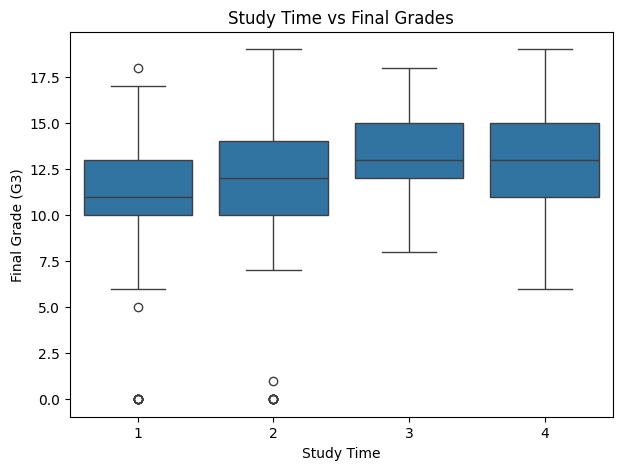

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x="studytime",
    y="G3",
    data=df
)

plt.title("Study Time vs Final Grades")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")

plt.show()

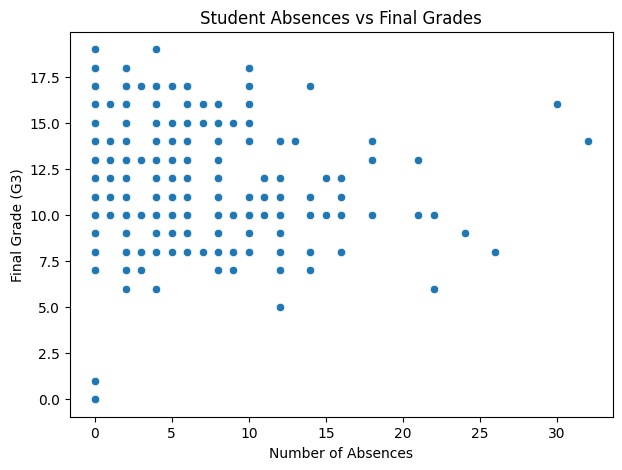

In [ ]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x="absences",
    y="G3",
    data=df
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.show()

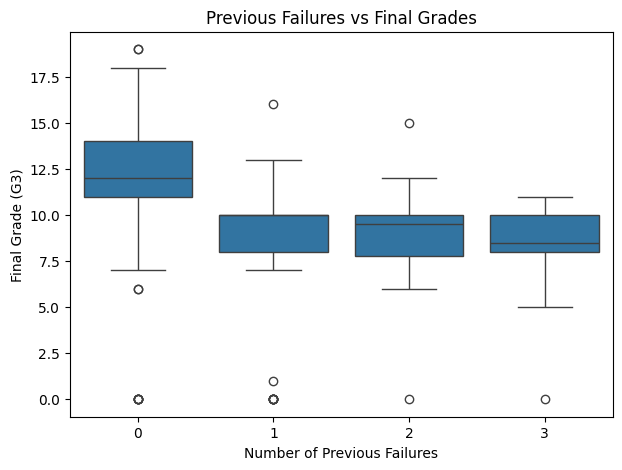

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x="failures",
    y="G3",
    data=df
)

plt.title("Previous Failures vs Final Grades")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade (G3)")

plt.show()

## 11. Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method is used to identify potential outliers in selected numerical columns. Potential outliers are counted but are not automatically removed, because they may represent genuine student records.


In [ ]:
columns_to_check = ["age", "absences", "G1", "G2", "G3"]
outlier_summary = []

for col in columns_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary.round(2))


,Variable,Lower Bound,Upper Bound,Potential Outliers
0,age,13.0,21.0,1
1,absences,-9.0,15.0,21
2,G1,5.5,17.5,16
3,G2,5.5,17.5,25
4,G3,4.0,20.0,16


### 11.1 Outlier Detection Findings

The earlier IQR calculation for this dataset identified:

- Age: 1 potential outlier
- Absences: 21 potential outliers
- G1: 16 potential outliers
- G2: 25 potential outliers
- G3: 16 potential outliers

G2 had the highest number of potential outliers (25). These records are retained for analysis and should be investigated before deciding whether any treatment is appropriate.


## 12. Overall Key Findings

The exploratory analysis of the 649 student records revealed the following:

1. The dataset contains 649 records and 33 columns.
2. No missing values or duplicate records were found.
3. The average final grade (G3) is approximately 11.91.
4. The final grade ranges from 0 to 19.
5. G1 and G2 have strong positive correlations with G3.
6. Study time has a positive association with final grades.
7. Previous failures have a negative association with final grades.
8. Absences have a weak negative Pearson correlation with final grades.
9. Spearman tests found statistically significant associations for study time, absences, and previous failures.
10. Potential outliers were identified and retained for further investigation.


## 13. Conclusion

Exploratory Data Analysis was performed on the Student Performance dataset containing 649 records and 33 columns.

The analysis included dataset inspection, data quality checks, descriptive statistics, comparisons across student-related factors, correlation analysis, hypothesis testing, and outlier detection.

The results show that previous academic grades are strongly associated with final grades. Study time, absences, and previous failures also show statistically significant associations with final grades in the Spearman tests.

The analysis provides a foundation for further interpretation through graphs and charts in **CodeAlpha Internship – Task 3: Data Visualization**.
